## Cell 1: Task 1 - Data Preparation & Preprocessing

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Load Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Preprocess: Resize 28x28 to 32x32 and convert grayscale to 3-channel RGB for MobileNetV2
X_train = tf.image.resize(X_train[..., tf.newaxis], (32, 32))
X_train = tf.repeat(X_train, 3, axis=-1) / 255.0

X_test = tf.image.resize(X_test[..., tf.newaxis], (32, 32))
X_test = tf.repeat(X_test, 3, axis=-1) / 255.0

print("Task 1 Complete - Data prepared successfully.")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Task 1 Complete - Data prepared successfully.


## Cell 2: Task 2 - Model Implementation

In [ ]:
# Load pretrained MobileNetV2 base model without top layers
base_model = MobileNetV2(input_shape=(32, 32, 3), include_top=False, weights='imagenet')

# Freeze base model layers
base_model.trainable = False

# Add custom classification head for 10 classes[cite: 1]
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("Task 2 Complete - Model implemented successfully.")

/tmp/ipykernel_2008/381913003.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=(32, 32, 3), include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Task 2 Complete - Model implemented successfully.


## Cell 3: Task 3 - Model Training

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Apply EarlyStopping to prevent overfitting[cite: 1]
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

# Train the model[cite: 1]
history = model.fit(
    X_train, y_train,
    epochs=4,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)

# Generate predictions for evaluation
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("Task 3 Complete - Model trained successfully.")

Epoch 1/4
750/750 ━━━━━━━━━━━━━━━━━━━━ 70s 80ms/step - accuracy: 0.4639 - loss: 1.6985 - val_accuracy: 0.5827 - val_loss: 1.4011
Epoch 2/4
750/750 ━━━━━━━━━━━━━━━━━━━━ 57s 76ms/step - accuracy: 0.5273 - loss: 1.4099 - val_accuracy: 0.6043 - val_loss: 1.2611
Epoch 3/4
750/750 ━━━━━━━━━━━━━━━━━━━━ 57s 76ms/step - accuracy: 0.5425 - loss: 1.3376 - val_accuracy: 0.6078 - val_loss: 1.2060
Epoch 4/4
750/750 ━━━━━━━━━━━━━━━━━━━━ 92s 89ms/step - accuracy: 0.5446 - loss: 1.3110 - val_accuracy: 0.6117 - val_loss: 1.1758
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step
Task 3 Complete - Model trained successfully.


## Cell 4: Accuracy & Precision Evaluation Cell

In [ ]:
# Calculate Accuracy and Precision
acc = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average='macro')
precision_weighted = precision_score(y_test, y_pred, average='weighted')

print("--- Accuracy & Precision Evaluation ---")
print(f"Overall Accuracy    : {acc * 100:.2f}%")
print(f"Macro Precision     : {precision_macro:.4f}")
print(f"Weighted Precision  : {precision_weighted:.4f}")

--- Accuracy & Precision Evaluation ---
Overall Accuracy    : 61.07%
Macro Precision     : 0.6350
Weighted Precision  : 0.6350


## Cell 5: Recall & F1-Score Evaluation Cell

In [ ]:
# Calculate Recall and F1-Score
recall_macro = recall_score(y_test, y_pred, average='macro')
recall_weighted = recall_score(y_test, y_pred, average='weighted')

f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print("--- Recall & F1-Score Evaluation ---")
print(f"Macro Recall        : {recall_macro:.4f}")
print(f"Weighted Recall     : {recall_weighted:.4f}")
print(f"Macro F1-Score      : {f1_macro:.4f}")
print(f"Weighted F1-Score   : {f1_weighted:.4f}")

--- Recall & F1-Score Evaluation ---
Macro Recall        : 0.6107
Weighted Recall     : 0.6107
Macro F1-Score      : 0.6076
Weighted F1-Score   : 0.6076


## Cell 6: Task 5 - Confusion Matrix & Result Analysis

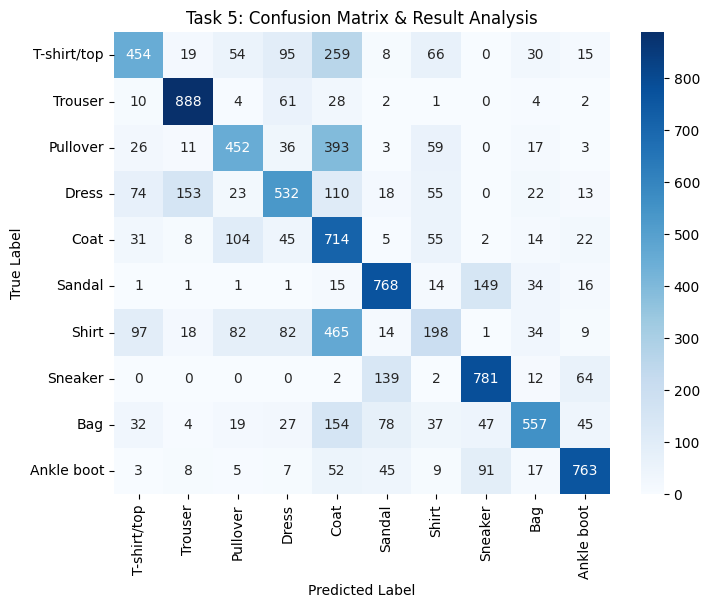

Task 5 Complete - Confusion matrix generated successfully.


In [ ]:
# Class names for Fashion-MNIST[cite: 1]
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Generate confusion matrix[cite: 1]
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Task 5: Confusion Matrix & Result Analysis')
plt.show()

print("Task 5 Complete - Confusion matrix generated successfully.")